In [1]:
%pip install -q --index-url https://pypi.org/simple "guidellm==0.8.1" pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, subprocess, pathlib

TARGET = "http://gpt-oss-20b-predictor.cfo-ai.svc.cluster.local:8080"
API_KEY = os.environ.get("LLM_TOKEN", "")
MODEL = "gpt-oss-20b"
TOKENIZER = "openai/gpt-oss-20b"

CONCURRENCY = [1, 2, 4, 8, 16]
DURATION_S = 30
PROMPT_TOKENS = 1000
OUTPUT_TOKENS = 256

RESULTS = pathlib.Path("results")
RESULTS.mkdir(exist_ok=True)

In [3]:
import urllib.request
req = urllib.request.Request(f"{TARGET}/v1/models",
                             headers={"Authorization": f"Bearer {API_KEY}"} if API_KEY else {})
print(urllib.request.urlopen(req, timeout=10).read()[:200])

b'{"object":"list","data":[{"id":"gpt-oss-20b","object":"model","created":1795194185,"owned_by":"vllm","root":"/mnt/models","parent":null,"max_model_len":32768,"permission":[{"id":"modelperm-d7844b8eb0b'


In [4]:
backend = {
    "kind": "openai_http",
    "target": TARGET,
    "model": MODEL,
    "extras": {"body": {"reasoning_effort": "low", "ignore_eos": False}},
}
if API_KEY:
    backend["api_key"] = API_KEY

for c in CONCURRENCY:
    out = RESULTS / f"c{c:02d}.json"
    cmd = [
        "guidellm", "run",
        "--backend", json.dumps(backend),
        "--tokenizer", f"kind=huggingface_auto,model={TOKENIZER}",
        "--data", f"kind=synthetic_text,prompt_tokens={PROMPT_TOKENS},output_tokens={OUTPUT_TOKENS}",
        "--profile", f"kind=concurrent,streams={c}",
        "--constraint", f"kind=max_duration,seconds={DURATION_S}",
        "--output", f"kind=json,path={out}",
        "--output", f"kind=html,path={RESULTS / f'c{c:02d}.html'}",
        "--disable-console",
    ]
    print(f"concurrency={c} ...", end=" ", flush=True)
    r = subprocess.run(cmd, capture_output=True, text=True)
    print("ok" if r.returncode == 0 and out.exists() else f"FAILED\n{r.stderr[-1500:]}")

concurrency=1 ... ok
concurrency=2 ... ok
concurrency=4 ... ok
concurrency=8 ... ok
concurrency=16 ... ok


In [5]:
import pandas as pd

rows = []
for f in sorted(RESULTS.glob("c*.json")):
    for b in json.load(open(f))["benchmarks"]:
        m = b["metrics"]
        ok = lambda k: m[k]["successful"]
        t = m["request_totals"]
        rows.append({
            "users": b["config"]["strategy"]["streams"],
            "ok": t["successful"], "errors": t["errored"],
            "TTFT p50, ms": round(ok("time_to_first_token_ms")["median"]),
            "TTFT p95, ms": round(ok("time_to_first_token_ms")["percentiles"]["p95"]),
            "tok/s per user": round(1000 / ok("inter_token_latency_ms")["median"], 1),
            "answer p50, s": round(ok("request_latency")["median"], 1),
            "output tok/answer": round(ok("output_token_count")["median"]),
            "server output tok/s": round(m["output_tokens_per_second"]["successful"]["mean"], 1),
            "requests/s": round(m["requests_per_second"]["successful"]["mean"], 2),
        })
df = pd.DataFrame(rows).sort_values("users").reset_index(drop=True)
df.to_csv(RESULTS / "summary.csv", index=False)
df

,users,ok,errors,"TTFT p50, ms","TTFT p95, ms",tok/s per user,"answer p50, s",output tok/answer,server output tok/s,requests/s
0,1,16,0,256,261,58.6,1.6,88,50.2,0.53
1,2,20,0,124,293,44.6,2.3,102,82.1,0.67
2,4,33,0,155,488,35.4,2.8,92,122.6,1.07
3,8,45,0,186,355,29.0,3.5,98,169.2,1.50
4,16,67,0,223,556,23.5,4.9,98,280.8,2.17


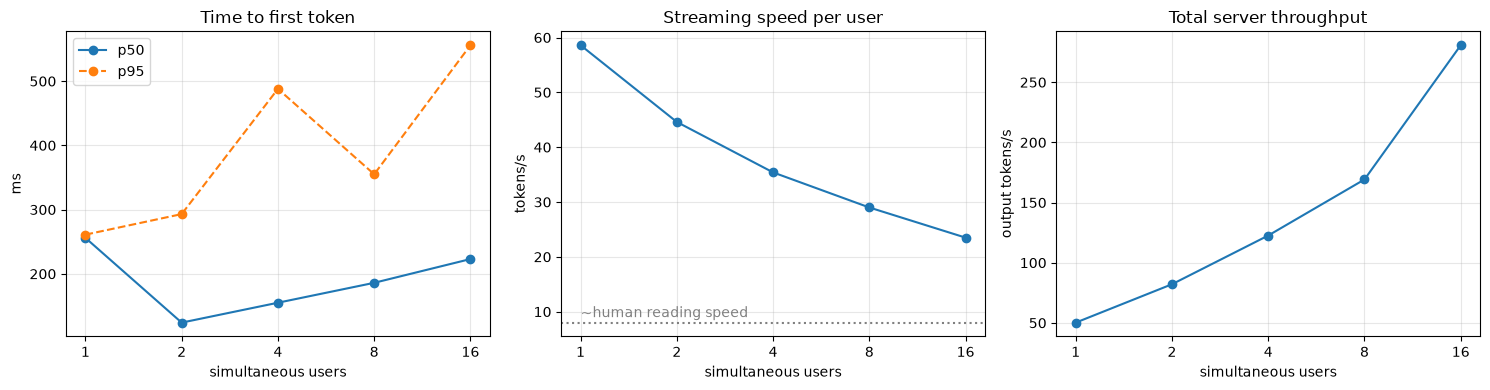

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(df["users"], df["TTFT p50, ms"], "o-", label="p50")
ax[0].plot(df["users"], df["TTFT p95, ms"], "o--", label="p95")
ax[0].set(title="Time to first token", xlabel="simultaneous users", ylabel="ms"); ax[0].legend()
ax[1].plot(df["users"], df["tok/s per user"], "o-")
ax[1].axhline(8, ls=":", c="gray"); ax[1].text(df["users"].iloc[0], 9, "~human reading speed", color="gray")
ax[1].set(title="Streaming speed per user", xlabel="simultaneous users", ylabel="tokens/s")
ax[2].plot(df["users"], df["server output tok/s"], "o-")
ax[2].set(title="Total server throughput", xlabel="simultaneous users", ylabel="output tokens/s")
for a in ax: a.set_xscale("log", base=2); a.set_xticks(df["users"], df["users"]); a.grid(alpha=.3)
plt.tight_layout()
plt.savefig(RESULTS / "benchmark.png", dpi=150)
plt.show()